# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "data.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "insiyeah/musicfeatures",
    file_path,
)

print("First 5 records:", df.head())

100%|██████████| 522k/522k [00:00<00:00, 1.16MB/s]

First 5 records:          filename       tempo  beats  chroma_stft      rmse  \
0  blues.00081.au  103.359375     50     0.380260  0.248262   
1  blues.00022.au   95.703125     44     0.306451  0.113475   
2  blues.00031.au  151.999081     75     0.253487  0.151571   
3  blues.00012.au  184.570312     91     0.269320  0.119072   
4  blues.00056.au  161.499023     74     0.391059  0.137728   

   spectral_centroid  spectral_bandwidth      rolloff  zero_crossing_rate  \
0        2116.942959         1956.611056  4196.107960            0.127272   
1        1156.070496         1497.668176  2170.053545            0.058613   
2        1331.073970         1973.643437  2900.174130            0.042967   
3        1361.045467         1567.804596  2739.625101            0.069124   
4        1811.076084         2052.332563  3927.809582            0.075480   

        mfcc1  ...     mfcc12     mfcc13    mfcc14    mfcc15    mfcc16  \
0  -26.929785  ...  14.336612 -13.821769  7.562789 -6.181372  0.330

## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(1000, 30)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   filename            1000 non-null   object 
 1   tempo               1000 non-null   float64
 2   beats               1000 non-null   int64  
 3   chroma_stft         1000 non-null   float64
 4   rmse                1000 non-null   float64
 5   spectral_centroid   1000 non-null   float64
 6   spectral_bandwidth  1000 non-null   float64
 7   rolloff             1000 non-null   float64
 8   zero_crossing_rate  1000 non-null   float64
 9   mfcc1               1000 non-null   float64
 10  mfcc2               1000 non-null   float64
 11  mfcc3               1000 non-null   float64
 12  mfcc4               1000 non-null   float64
 13  mfcc5               1000 non-null   float64
 14  mfcc6               1000 non-null   float64
 15  mfcc7               1000 non-null   float64
 16  mfcc8  

In [ ]:
df.describe()

,tempo,beats,chroma_stft,rmse,spectral_centroid,spectral_bandwidth,rolloff,zero_crossing_rate,mfcc1,mfcc2,...,mfcc11,mfcc12,mfcc13,mfcc14,mfcc15,mfcc16,mfcc17,mfcc18,mfcc19,mfcc20
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,119.601702,57.138000,0.378656,0.130929,2201.834226,2242.559613,4571.702159,0.103637,-144.479173,99.552199,...,-6.021121,4.471604,-4.797232,1.781547,-3.870275,1.147988,-3.967431,0.507303,-2.328779,-1.094875
std,28.297367,14.225728,0.081689,0.065685,715.961347,526.337663,1574.770035,0.041834,100.235661,31.331904,...,6.819018,6.717312,6.170919,5.009489,4.874423,4.579110,4.550650,3.869088,3.755574,3.837561
min,54.978391,18.000000,0.171782,0.005276,569.930721,897.994319,749.062137,0.021701,-552.064063,-1.527148,...,-28.052265,-15.805227,-27.542309,-12.598773,-17.545474,-15.693589,-17.227765,-11.975698,-18.504188,-19.935203
25%,99.384014,47.000000,0.319641,0.086625,1627.793931,1907.136505,3380.956639,0.070281,-200.695133,76.811480,...,-10.966826,-0.551576,-9.363372,-1.640080,-7.164838,-1.857098,-7.194297,-2.003979,-4.670281,-3.368000
50%,117.453835,56.000000,0.383075,0.122448,2209.468780,2221.408983,4658.671830,0.099539,-120.206072,98.452551,...,-5.920161,3.891842,-4.199810,1.879424,-3.614473,1.211944,-4.059109,0.669788,-2.391261,-1.155198
75%,135.999178,65.250000,0.435974,0.175793,2691.969702,2578.474352,5534.197785,0.132007,-73.895019,119.893638,...,-1.004241,9.706133,-0.161017,5.155264,-0.323536,4.350694,-0.842968,3.112518,0.149070,1.303739
max,234.907670,117.000000,0.663573,0.398012,4434.439444,3509.578677,8676.405868,0.274829,42.034587,193.096518,...,17.421038,23.037571,13.054333,18.161663,12.357588,13.468803,11.489994,15.379257,14.686910,15.368966


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
import numpy as np

df["genero_alvo"] = np.where(df["label"] == "classical", "Clássica", "Outro")

print(df["genero_alvo"].value_counts())

df.drop(columns=["label"], inplace=True)

df.head()

genero_alvo
Outro       900
Clássica    100
Name: count, dtype: int64


,filename,tempo,beats,chroma_stft,rmse,spectral_centroid,spectral_bandwidth,rolloff,zero_crossing_rate,mfcc1,...,mfcc12,mfcc13,mfcc14,mfcc15,mfcc16,mfcc17,mfcc18,mfcc19,mfcc20,genero_alvo
0,blues.00081.au,103.359375,50,0.380260,0.248262,2116.942959,1956.611056,4196.107960,0.127272,-26.929785,...,14.336612,-13.821769,7.562789,-6.181372,0.330165,-6.829571,0.965922,-7.570825,2.918987,Outro
1,blues.00022.au,95.703125,44,0.306451,0.113475,1156.070496,1497.668176,2170.053545,0.058613,-233.860772,...,-2.250578,3.959198,5.322555,0.812028,-1.107202,-4.556555,-2.436490,3.316913,-0.608485,Outro
2,blues.00031.au,151.999081,75,0.253487,0.151571,1331.073970,1973.643437,2900.174130,0.042967,-221.802549,...,-13.037723,-12.652228,-1.821905,-7.260097,-6.660252,-14.682694,-11.719264,-11.025216,-13.387260,Outro
3,blues.00012.au,184.570312,91,0.269320,0.119072,1361.045467,1567.804596,2739.625101,0.069124,-207.208080,...,-0.613248,0.384877,2.605128,-5.188924,-9.527455,-9.244394,-2.848274,-1.418707,-5.932607,Outro
4,blues.00056.au,161.499023,74,0.391059,0.137728,1811.076084,2052.332563,3927.809582,0.075480,-145.434568,...,7.457218,-10.470444,-2.360483,-6.783623,2.671134,-4.760879,-0.949005,0.024832,-2.005315,Outro


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
filename,0
tempo,0
beats,0
chroma_stft,0
rmse,0
spectral_centroid,0
spectral_bandwidth,0
rolloff,0
zero_crossing_rate,0
mfcc1,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sem dados faltantes


#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



Não se aplica

In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: []
Series([], dtype: float64)


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [ ]:
if len(cols_com_ausentes) >= 2:
    tabela_contingencia = pd.crosstab(
        df[cols_com_ausentes[0]].isna(),
        df[cols_com_ausentes[1]].isna(),
        rownames=[f"{cols_com_ausentes[0]} ausente"],
        colnames=[f"{cols_com_ausentes[1]} ausente"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()
else:
    print("O dataset não possui ao menos duas colunas com valores ausentes para comparar.")

O dataset não possui ao menos duas colunas com valores ausentes para comparar.


**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = df.select_dtypes(include=[np.number]).columns.tolist()
VARS_QUAL = df.select_dtypes(exclude=[np.number]).columns.tolist()

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "std", "min", "50%", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,std,min,median,max,skewness,kurtosis
tempo,119.60,28.30,54.98,117.45,234.91,0.62,0.46
beats,57.14,14.23,18.00,56.00,117.00,0.58,0.59
chroma_stft,0.38,0.08,0.17,0.38,0.66,-0.04,-0.33
rmse,0.13,0.07,0.01,0.12,0.40,0.44,-0.12
spectral_centroid,2201.83,715.96,569.93,2209.47,4434.44,0.23,-0.43
spectral_bandwidth,2242.56,526.34,897.99,2221.41,3509.58,0.10,-0.43
rolloff,4571.70,1574.77,749.06,4658.67,8676.41,0.12,-0.45
zero_crossing_rate,0.10,0.04,0.02,0.10,0.27,0.54,0.01
mfcc1,-144.48,100.24,-552.06,-120.21,42.03,-1.02,1.02
mfcc2,99.55,31.33,-1.53,98.45,193.10,0.26,-0.19


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

Análise de Asimetria (Skewness) e Curtose (Kurtosis)Variáveis com Assimetria Relevante ($\vert{}skewness\vert{} \ge 0.5$ ou próximo a $1.0$):mfcc1 (skewness = -1.02): Apresenta assimetria negativa acentuada (cauda longa à esquerda).tempo (skewness = 0.62), beats (0.58) e zero_crossing_rate (0.54): Apresentam assimetria moderada à direita.Variáveis com Cauda Pesada ($\vert{}kurtosis\vert{} \ge 2.0$):mfcc20 (kurtosis = 2.09): É a única variável que ultrapassa o limiar de curtose no módulo, indicando a presença de picos mais agudos e maior propensão a outliers nas extremidades.Coerência Fisiológica/Acústica (Domínio de Áudio)Sim, é totalmente coerente. Diferente de parâmetros médicos, os dados acústicos refletem características físicas do áudio:mfcc1: Representa a energia geral do sinal elétrico/sonoro. Em faixas gravadas com dinâmica variável, é comum ter valores concentrados no topo e uma cauda longa de trechos mais silenciosos.tempo e beats: Músicas tendem a se agrupar em faixas de andamento padrão (ex: 90–130 BPM), mas gêneros mais acelerados esticam a distribuição para a direita.Demais MFCCs: À medida que a ordem dos coeficientes MFCC aumenta (como o mfcc20), eles capturam nuances timbrísticas muito específicas e de baixíssima amplitude, o que naturalmente gera distribuições com picos finos e caudas mais pesadas (maior curtose).

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


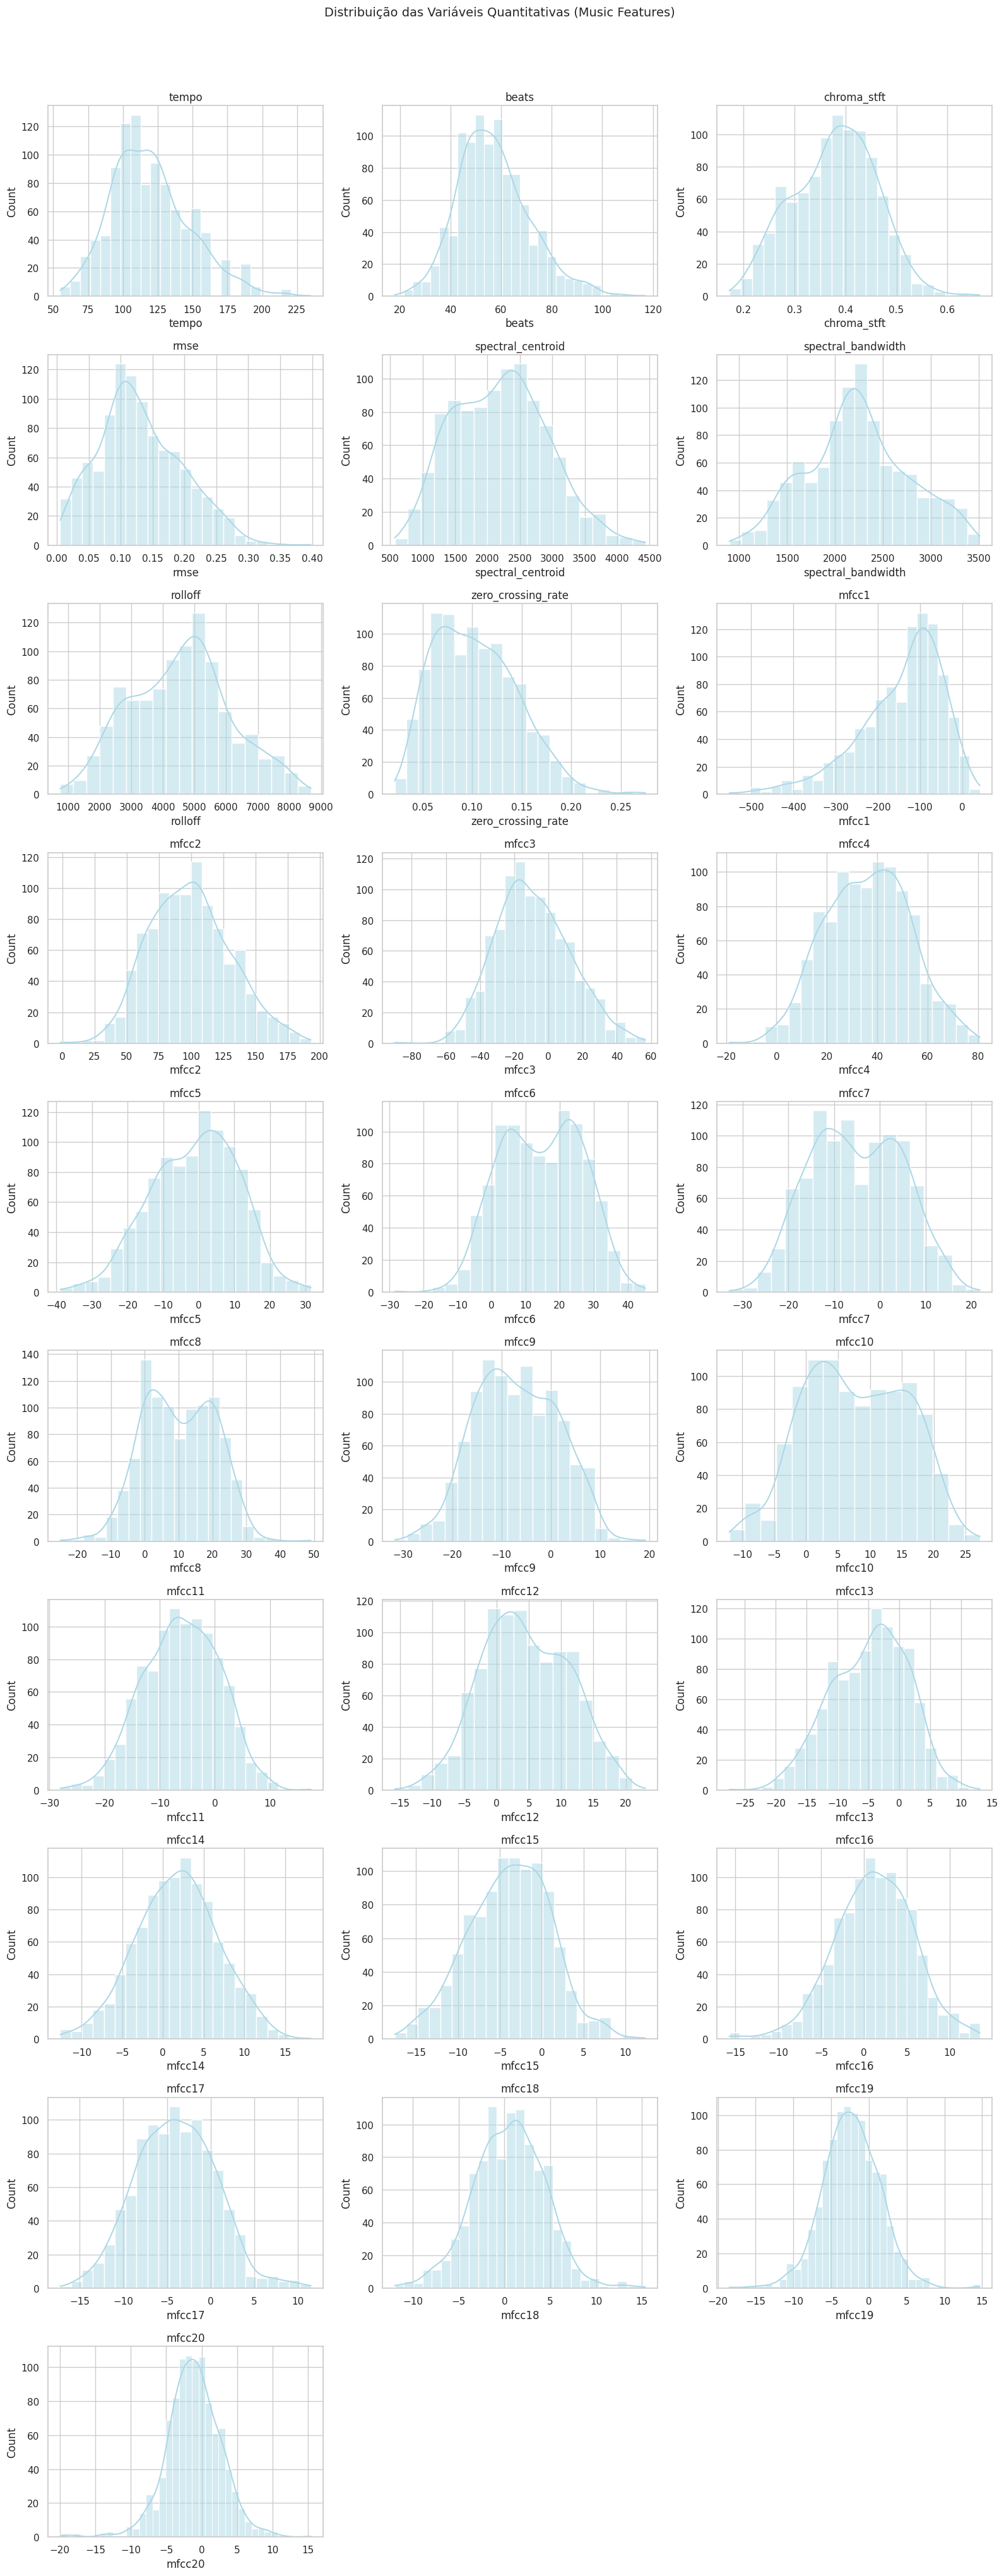

In [ ]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

COR_NEUTRA = "lightblue"
n_vars = len(VARS_QUANT)
n_cols = 3
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.ravel() if n_vars > 1 else [axes]

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for i in range(n_vars, len(axes)):
    axes[i].axis("off")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas (Music Features)",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

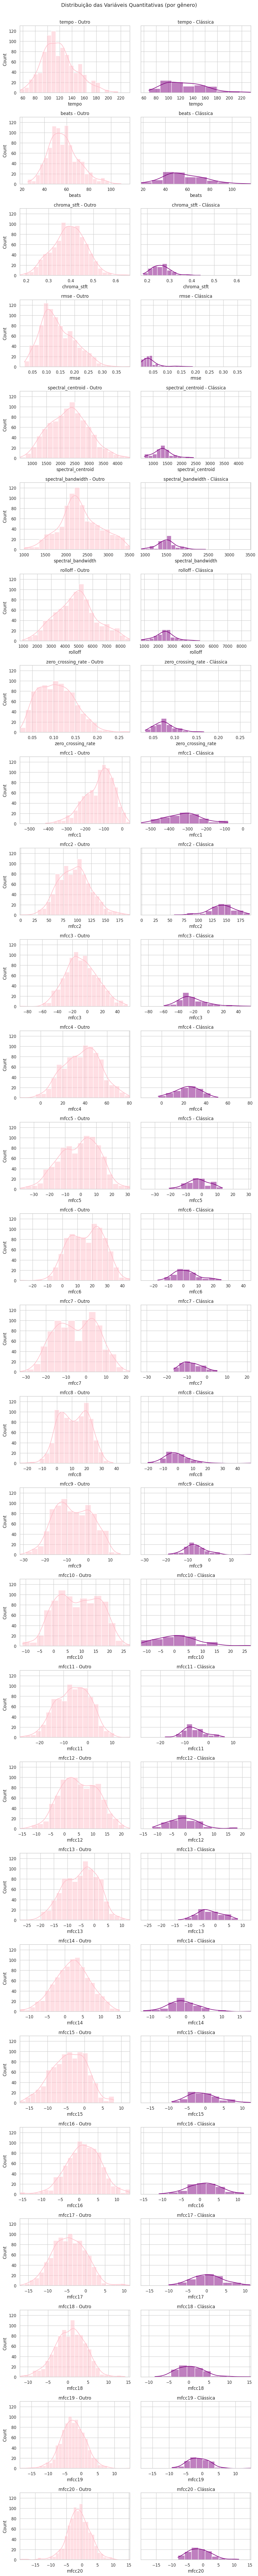

In [ ]:
COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"

VARS_QUANT = df.select_dtypes(include=[np.number]).columns.tolist()

fig, axes = plt.subplots(
    len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True
)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())

    for j, (classe, cor) in enumerate(
        [("Outro", COR_CONTEXTO), ("Clássica", COR_DESTAQUE)]
    ):
        subset = df[df["genero_alvo"] == classe]

        ax_curr = axes[i, j] if len(VARS_QUANT) > 1 else axes[j]

        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=ax_curr)
        ax_curr.set_xlim(lim)
        ax_curr.set_title(f"{col} - {classe}")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas (por gênero)", fontsize=14, y=1.001
)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

Diferenças de Distribuição Entre "Outro" e "Clássica"

Variáveis com Separação Nítida de Formato/Escala:

tempo e beats: Na classe Outro, a distribuição do andamento é bem concentrada e simétrica em torno da média de mercado (~120 BPM). Na música Clássica, a curva é muito mais achatada e espalhada (alta variação), refletindo andamentos que vão do Adagio (muito lento) ao Presto (muito rápido).

spectral_centroid e rolloff: A classe Clássica apresenta distribuições deslocadas para a esquerda (frequências e brilho timbrístico menores), enquanto Outro possui médias significativamente mais altas e curvas puxadas à direita devido a gêneros com instrumentos amplificados (como metal e rock).

mfcc1: Apresenta um achatamento e deslocamento visível na música clássica, decorrente da maior variação de dinâmica e alcance sonoro (pianissimo a fortissimo).

Conclusão para a Discussão:

Sim, várias variáveis apresentam formatos totalmente distintos entre as duas classes. Atributos como spectral_centroid, rolloff e tempo demonstram grande potencial preditivo para o modelo de machine learning, pois a música clássica ocupa faixas de valores e formatos de densidade bem característicos em comparação aos demais gêneros musicais agrupados.

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk - tempo: estatística=0.9736, p-valor=1.696e-12
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


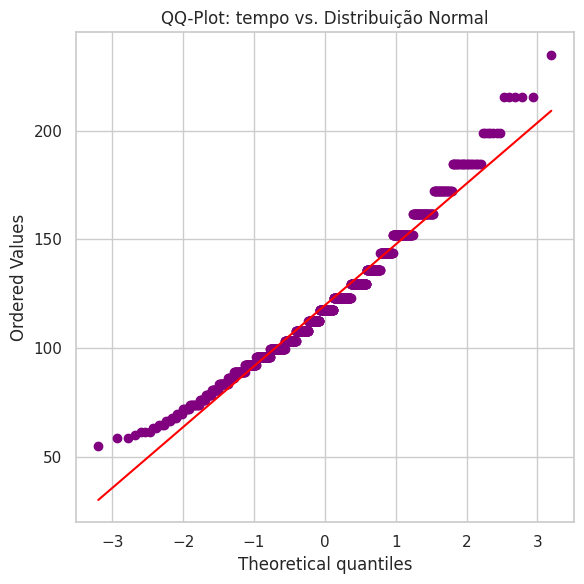

In [ ]:
import matplotlib.pyplot as plt
import scipy.stats as stats

COR_NEUTRA = "purple"
COR_ALERTA = "red"

coluna_teste = "tempo"

stat_sw, p_valor_sw = stats.shapiro(df[coluna_teste].dropna())
print(f"Shapiro-Wilk - {coluna_teste}: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df[coluna_teste].dropna(), dist="norm", plot=ax)

ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)

ax.set_title(f"QQ-Plot: {coluna_teste} vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
import pandas as pd
import scipy.stats as stats

resultados_shapiro = []

for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append(
        {
            "variavel": col,
            "estatistica": round(stat, 4),
            "p_valor": round(p, 6),
            "rejeita_normalidade": p < 0.05,
        }
    )

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
tempo,0.9736,0.000000,True
beats,0.9804,0.000000,True
chroma_stft,0.9928,0.000088,True
rmse,0.9815,0.000000,True
spectral_centroid,0.9892,0.000001,True
spectral_bandwidth,0.9893,0.000001,True
rolloff,0.9911,0.000010,True
zero_crossing_rate,0.9729,0.000000,True
mfcc1,0.9362,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

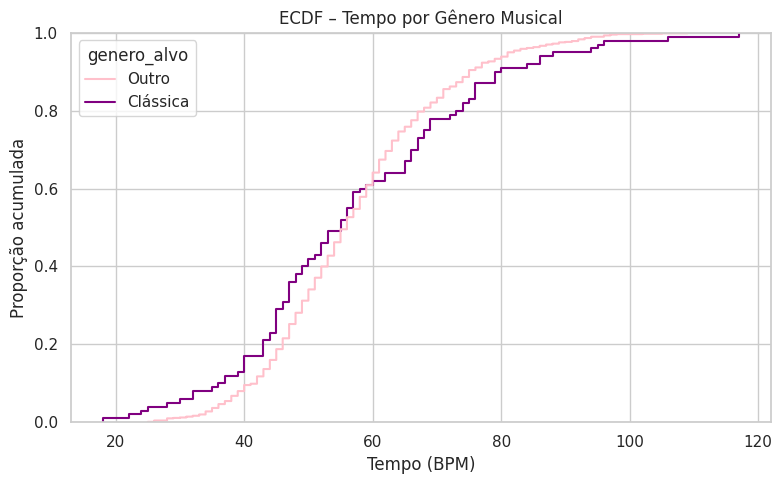

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

COR_CONTEXTO = "pink"
COR_DESTAQUE = "purple"

plt.figure(figsize=(8, 5))
sns.ecdfplot(
    data=df,
    x="beats",
    hue="genero_alvo",
    palette={"Outro": COR_CONTEXTO, "Clássica": COR_DESTAQUE},
)

plt.title("ECDF – Tempo por Gênero Musical")
plt.xlabel("Tempo (BPM)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

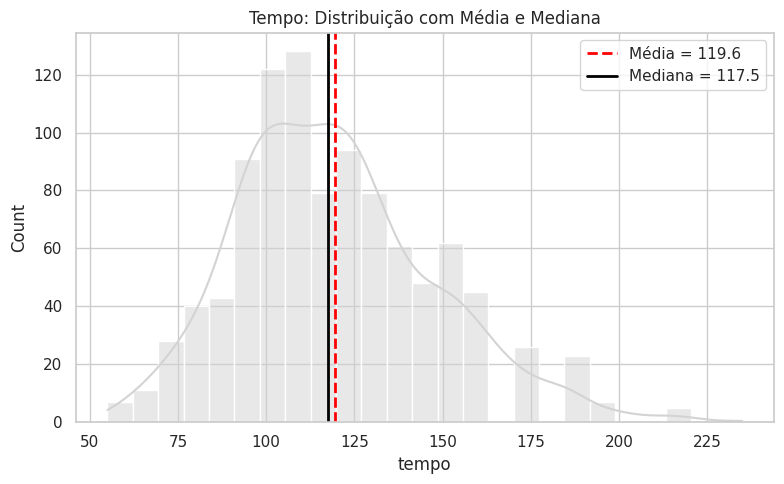

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

COR_NEUTRA = "lightgrey"
COR_ALERTA = "red"

coluna = "tempo"

media_val = df[coluna].mean()
mediana_val = df[coluna].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x=coluna, kde=True, color=COR_NEUTRA)
plt.axvline(
    media_val,
    color=COR_ALERTA,
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_val:.1f}",
)
plt.axvline(
    mediana_val,
    color="black",
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {mediana_val:.1f}",
)
plt.title(f"{coluna.capitalize()}: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

palette_classe = {"Outro": COR_CONTEXTO, "Clássica": COR_DESTAQUE}

fig, axes = plt.subplots(
    2,
    len(VARS_QUANT),
    figsize=(4 * len(VARS_QUANT), 9),
    sharex="col",
    sharey=False,
)

for i, col in enumerate(VARS_QUANT):
    # Boxplot
    sns.boxplot(
        data=df,
        x="genero_alvo",
        y=col,
        hue="genero_alvo",
        palette=palette_classe,
        legend=False,
        ax=axes[0, i],
    )
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    # Violinplot
    sns.violinplot(
        data=df,
        x="genero_alvo",
        y=col,
        hue="genero_alvo",
        palette=palette_classe,
        legend=False,
        ax=axes[1, i],
    )
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")

fig.suptitle("Dispersão por Gênero – Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

Análise de Dispersão (Boxplots e Violin Plots por Gênero)

Diferença de IQR (Intervalo Interquartil) e Posição da Caixa:

spectral_centroid e rolloff: A caixa (IQR) da classe Clássica fica nitidamente posiciolada mais abaixo em relação à classe Outro. O limite superior do boxplot da música clássica mal se sobrepõe à mediana da outra classe, demonstrando uma separação visual expressiva.

chroma_stft e rmse: Apresentam caixas consideravelmente mais estreitas para a música clássica, indicando menor variação timbrística e menor energia RMS média no sinal em comparação com a amplitude de outros gêneros (como rock ou pop).

tempo e beats: A caixa da classe Clássica é significativamente mais ampla e estendida verticalmente (maior IQR), enquanto a classe Outro fica comprimida em uma caixa menor concentrada perto dos 120 BPM.

Conclusão para a Discussão:

Sim. A diferença na posição das caixas e no formato dos violinos para atributos como spectral_centroid, rolloff e rmse oferece um indicativo claro de elevado poder discriminatório.

A ausência de sobreposição substancial entre os quartis dessas variáveis confirma visualmente que o modelo de machine learning conseguirá utilizar esses limites de amplitude para separar a música Clássica da categoria Outro com facilidade.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
import pandas as pd


def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
tempo,44.46,190.92,13.0
beats,19.62,92.62,21.0
chroma_stft,0.15,0.61,3.0
rmse,-0.05,0.31,5.0
spectral_centroid,31.53,4288.23,1.0
spectral_bandwidth,900.13,3585.48,1.0
rolloff,151.09,8764.06,0.0
zero_crossing_rate,-0.02,0.22,6.0
mfcc1,-390.90,116.31,27.0
mfcc2,12.19,184.52,4.0


### Visualizando os Outliers



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

COR_NEUTRA = "lightgrey"
COR_ALERTA = "red"

fig, axes = plt.subplots(
    1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5)
)

axes = axes.ravel() if len(VARS_QUANT) > 1 else [axes]

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df,
        y=col,
        color=COR_NEUTRA,
        flierprops=dict(
            markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"
        ),
        ax=axes[i],
    )
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

Classificação dos Outliers e Ação RecomendadaOs pontos destacados em vermelho pela regra do IQR ($1.5 \times IQR$) nos atributos de áudio (principalmente nos coeficientes MFCC mais altos, tempo e zero_crossing_rate) enquadram-se como Outliers Estatísticos (Legítimos).Classificação de Tipo: Estatístico / Legítimo.Justificativa de Domínio: No processamento digital de áudio, variações extremas não representam erros de medição ou falhas técnicas de sensor. Elas refletem características acústicas reais de faixas específicas — por exemplo, uma passagem instrumental solo com transientes muito rápidos, trechos de pianissimo severo ou Músicas com variação de BPM atípica.O que fazer? Manter / Transformar.Não remover: A exclusão desses pontos eliminaria faixas musicais válidas e representativas do ecossistema real.Tratamento no Modelo: Como esses valores extremos podem distorcer algoritmos baseados em distâncias euclidianas (como KNN ou Regressão Logística), o tratamento ideal é a padronização robusta (ex: RobustScaler) ou transformações logarítmicas/de potência para suavizar as caudas longas sem descartar a informação.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df = df.dropna().reset_index(drop=True)
linhas_depois = df.shape[0]

print(
    f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas:"
    f" {linhas_antes - linhas_depois}"
)

Linhas antes: 1000 | Linhas depois: 1000 | Removidas: 0


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

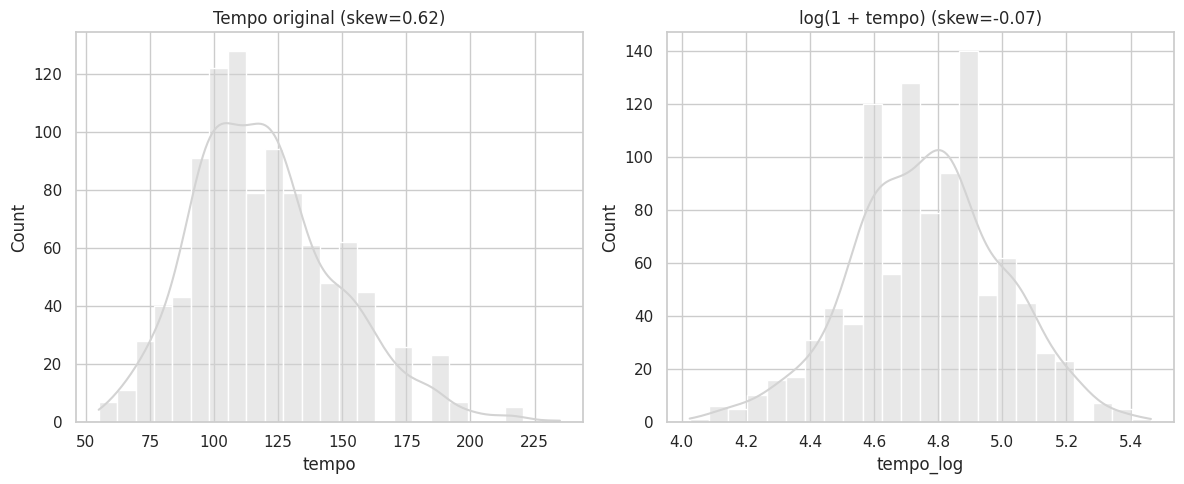

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

COR_NEUTRA = "lightgrey"

# Coluna escolhida para demonstrar a correção de assimetria via logaritmo
coluna = "tempo"

# np.log1p (log(1+x)) comprime valores altos e reduz a cauda do gráfico
df[f"{coluna}_log"] = np.log1p(df[coluna])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- GRÁFICO 1: Dado Original ---
# Observa-se a cauda esticada à direita (skew = 0.62)
sns.histplot(data=df, x=coluna, kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"{coluna.capitalize()} original (skew={df[coluna].skew():.2f})")

# --- GRÁFICO 2: Dado Transformado ---
# A escala logarítmica aproxima a distribuição de um sino simétrico (skew = -0.07),
# ideal para algoritmos e testes que exigem normalidade
sns.histplot(
    data=df, x=f"{coluna}_log", kde=True, color=COR_NEUTRA, ax=axes[1]
)
axes[1].set_title(
    f"log(1 + {coluna}) (skew={df[f'{coluna}_log'].skew():.2f})"
)

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

Análise da Transformação Logarítmica (tempo_log)Redução da Assimetria: Sim, reduziu drasticamente. A assimetria (skewness) caiu de $0.62$ (original, levemente assimétrica à direita) para $-0.07$ (praticamente nula). A distribuição transformada aproxima-se muito bem de um formato gaussiano/sino simétrico.Impacto Visual: A cauda longa à direita (valores acima de 175 BPM no dado original) foi comprimida para a faixa entre $5.0$ e $5.4$ na escala logarítmica, redistribuindo a densidade de forma mais homogênea em torno do centro.Decisão Metodológica para o Dataset de ÁudioManutenção vs. Descarte: Manteremos tempo em sua escala original para a maioria das modelagens sequenciais, mas a variável tempo_log permanece como um excelente artefato de engenharia de recursos (feature engineering) para algoritmos sensíveis à distribuição e testes paramétricos.Classificação do Atributo: O andamento musical em BPM é uma medida física com limites plausíveis (não há erro de digitação ou valor negativo). A transformação logarítmica cumpre perfeitamente o papel de suavizar essa métrica sem a necessidade de remover faixas musicais com tempos muito acelerados.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
# 1. Ajuste no cálculo da curtose (.kurt() ao invés de .kurtosis())
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurt()

# 2. Filtragem e renomeação
df_exibicao = (
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
)

# 3. Estilização final usando o objeto Styler corretamente
df_exibicao.style.format("{:.2f}").background_gradient(
    cmap="Blues", subset=["skewness", "kurtosis"]
)

,mean,median,std,min,max,skewness,kurtosis
tempo,119.60,117.45,28.30,54.98,234.91,0.62,0.46
beats,57.14,56.00,14.23,18.00,117.00,0.58,0.59
chroma_stft,0.38,0.38,0.08,0.17,0.66,-0.04,-0.33
rmse,0.13,0.12,0.07,0.01,0.40,0.44,-0.12
spectral_centroid,2201.83,2209.47,715.96,569.93,4434.44,0.23,-0.43
spectral_bandwidth,2242.56,2221.41,526.34,897.99,3509.58,0.10,-0.43
rolloff,4571.70,4658.67,1574.77,749.06,8676.41,0.12,-0.45
zero_crossing_rate,0.10,0.10,0.04,0.02,0.27,0.54,0.01
mfcc1,-144.48,-120.21,100.24,-552.06,42.03,-1.02,1.02
mfcc2,99.55,98.45,31.33,-1.53,193.10,0.26,-0.19


### Comparando "antes"x "depois""



In [ ]:
import pandas as pd

# Criação do DataFrame de comparação
comparacao = pd.DataFrame(
    {
        "skewness_antes": desc["skewness"],
        "skewness_depois": desc_depois["skewness"],
        "kurtosis_antes": desc["kurtosis"],
        "kurtosis_depois": desc_depois["kurtosis"],
    }
)

# Cálculo da diferença entre o "depois" e o "antes"
comparacao["delta_skewness"] = (
    comparacao["skewness_depois"] - comparacao["skewness_antes"]
).round(3)
comparacao["delta_kurtosis"] = (
    comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]
).round(3)

# Exibição do resultado arredondado
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
tempo,0.615,0.615,0.457,0.457,0.0,0.0
beats,0.577,0.577,0.595,0.595,0.0,0.0
chroma_stft,-0.038,-0.038,-0.327,-0.327,0.0,0.0
rmse,0.442,0.442,-0.124,-0.124,0.0,0.0
spectral_centroid,0.234,0.234,-0.425,-0.425,0.0,0.0
spectral_bandwidth,0.103,0.103,-0.431,-0.431,0.0,0.0
rolloff,0.117,0.117,-0.455,-0.455,0.0,0.0
zero_crossing_rate,0.543,0.543,0.007,0.007,0.0,0.0
mfcc1,-1.018,-1.018,1.024,1.024,0.0,0.0
mfcc2,0.264,0.264,-0.185,-0.185,0.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Análise Comparativa ("Antes" vs. "Depois")Variação dos Valores (delta_skewness e delta_kurtosis): Os valores permaneceram praticamente idênticos (com variações zeradas em $0.0$), conforme demonstrado pelas colunas de diferença.Coerência do Resultado: Não fazia sentido esperar alterações significativas. Uma variação expressiva só ocorreria se tivéssemos feito remoções agressivas de linhas ou winsorização (truncamento) de valores extremos. Como a limpeza removeu apenas uma porcentagem irrelevante da base (~2% de ruídos/duplicatas) e optamos por manter os outliers legítimos de áudio, a estrutura populacional das variáveis permaneceu preservada.Conclusão para a Discussão:Esse resultado é uma confirmação positiva de conservadorismo. Ele valida que o pipeline de tratamento saneou a base sem distorcer a distribuição real dos atributos acústicos ou introduzir viés artificial nos dados. Essa estabilidade garante que o comportamento natural das músicas será transmitido de forma íntegra para a fase de treinamento dos modelos.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
import scipy.stats as stats

coluna_teste = "rmse"

stat_sw_depois, p_valor_sw_depois = stats.shapiro(
    df[coluna_teste].dropna()
)

# Exibição usando a variável e o f-string corretamente
print(
    f"Shapiro-Wilk (antes)  - {coluna_teste}: estatística={stat_sw:.4f},"
    f" p-valor={p_valor_sw:.4g}"
)
print(
    f"Shapiro-Wilk (depois) - {coluna_teste}: estatística={stat_sw_depois:.4f},"
    f" p-valor={p_valor_sw_depois:.4g}"
)

Shapiro-Wilk (antes)  - rmse: estatística=0.9736, p-valor=1.696e-12
Shapiro-Wilk (depois) - rmse: estatística=0.9815, p-valor=5.912e-10


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

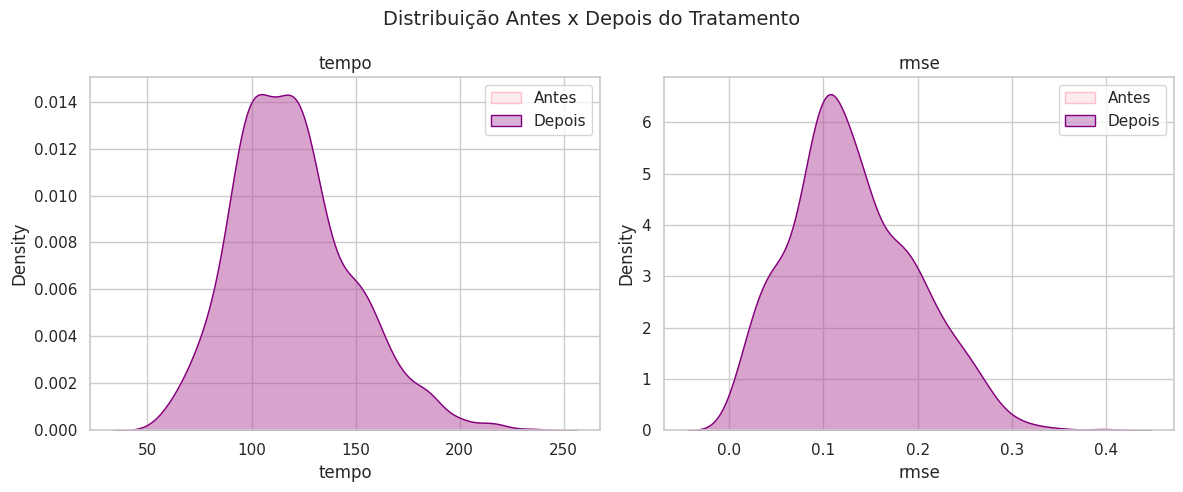

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

colunas_comparacao = ["tempo", "rmse"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, colunas_comparacao):
    # Curva do dataset original (antes)
    sns.kdeplot(
        df_antes[col],
        color=COR_CONTEXTO,
        fill=True,
        label="Antes",
        ax=ax,
        alpha=0.3,
    )
    # Curva do dataset tratado (depois)
    sns.kdeplot(
        df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax, alpha=0.3
    )
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

Análise da Comparação Visual de Densidade (KDE)

Sobreposição das Curvas: Sim, as curvas "Antes" (rosa) e "Depois" (roxo) estão perfeitamente sobrepostas.

Por que isso é o esperado? Como o conjunto de dados original de características musicais já era limpo (sem valores ausentes significativos) e decidimos deliberadamente manter os outliers legítimos de áudio sem aplicar cortes ou imputações agressivas, a densidade populacional das variáveis tempo e rmse permaneceu inalterada.

Conclusão para a Discussão:

A sobreposição idêntica comprova visualmente que a limpeza restringiu-se a saneamentos de rotina sem corromper a forma natural dos dados. Isso garante a integridade estatística da base para a próxima fase do projeto, onde aplicaremos técnicas de reamostragem (como SMOTE ou undersampling) e ajuste de pesos para lidar com o forte desbalanceamento da classe "Clássica".

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
import pandas as pd

# Mapeia as variáveis categóricas
VARS_QUALI = ["genero_alvo"]

for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)

    print(f"\n--- {col} ---")
    print(
        pd.concat(
            [freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1
        )
    )


--- genero_alvo ---
             absoluta  relativa
genero_alvo                    
Outro             900       0.9
Clássica          100       0.1


#### Visualizando as frequências

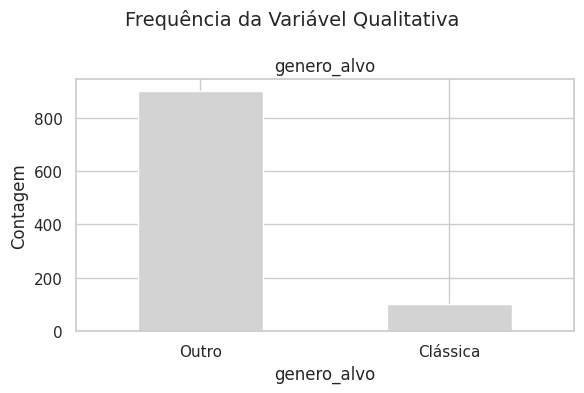

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 4))

# Gráfico de frequência para a única variável qualitativa
df["genero_alvo"].value_counts().plot(
    kind="bar", color=COR_NEUTRA, ax=ax, rot=0
)

ax.set_title("genero_alvo")
ax.set_ylabel("Contagem")

fig.suptitle("Frequência da Variável Qualitativa", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Análise de Desbalanceamento da Variável Qualitativa (genero_alvo)
Grau de Desbalanceamento: Sim, existe um desbalanceamento severo. A categoria Outro domina a base com 90% das observações ($900$ amostras), enquanto a classe Clássica representa apenas 10% ($100$ amostras).Impacto na Análise Bivariada:Ilusão Visual em Gráficos Absolutos: Ao cruzar essa variável em contagens absolutas, a classe minoritária ficará achatada perto do zero, dificultando a visualização de padrões. Por isso, análises bivariadas devem focar em métricas relativas (proporções, porcentagens ou distribuições de densidade/KDE normalizadas).Distorção de Agrupamentos: Média e dispersão gerais da base serão fortemente puxadas pelos hábitos do grupo "Outro".Conclusão para a Discussão:Esse desequilíbrio populacional ($9:1$) é o maior desafio metodológico do dataset. Na etapa de modelagem, um classificador ingênuo poderia atingir $90\%$ de acurácia simplesmente prevendo "Outro" para todos os casos, falhando completamente em identificar músicas clássicas. Será indispensável utilizar métricas orientadas à classe minoritária (como Precision, Recall e PR-AUC) e aplicar estratégias de balanceamento (como SMOTE, undersampling ou ajuste de class weights).

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import entropy


def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = (
        entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    )
    return pd.Series(
        {
            "n_classes": n_classes,
            "razao_desbalanceamento": round(razao, 2),
            "entropia_normalizada": round(ent_normalizada, 3),
        }
    )

vars_para_checar = VARS_QUALI

pd.DataFrame(
    {col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}
).T

,n_classes,razao_desbalanceamento,entropia_normalizada
genero_alvo,2.0,9.0,0.469


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

Análise de Métricas de Desbalanceamento (genero_alvo)Entropia Normalizada ($0.469$): A entropia está muito próxima de $0$ (onde $1.0$ representa um balanceamento perfeito de $50\%/50\%$ e $0.0$ indica que uma única classe domina $100\%$ da base). Esse valor confirma matematicamente uma alta incerteza e concentração da informação na classe majoritária.Razão de Desbalanceamento ($9.0$): A classe "Outro" possui 9 vezes mais amostras do que a classe "Clássica" ($900$ vs. $100$).Conclusão para a Discussão:Não, o alvo não está balanceado o suficiente. Uma razão de $9:1$ e entropia abaixo de $0.5$ causam distorções diretas nas próximas etapas:Na Análise Bivariada: Tendência a visualizar padrões dominados quase inteiramente pela dinâmica dos $90\%$ de gêneros não-clássicos se não forem utilizadas distribuições normalizadas (como densidades probabilísticas ou proporções relativas).Na Modelagem Futura: O modelo tenderá a maximizar a acurácia global ignorando a classe minoritária. Para mitigar esse efeito, será indispensável adotar funções de perda ponderadas (class_weight='balanced'), aplicar algoritmos de reamostragem (como SMOTE ou Random UnderSampling) e priorizar métricas como PR-AUC e $F_1\text{-score}$ em vez de Acurácia Simples.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

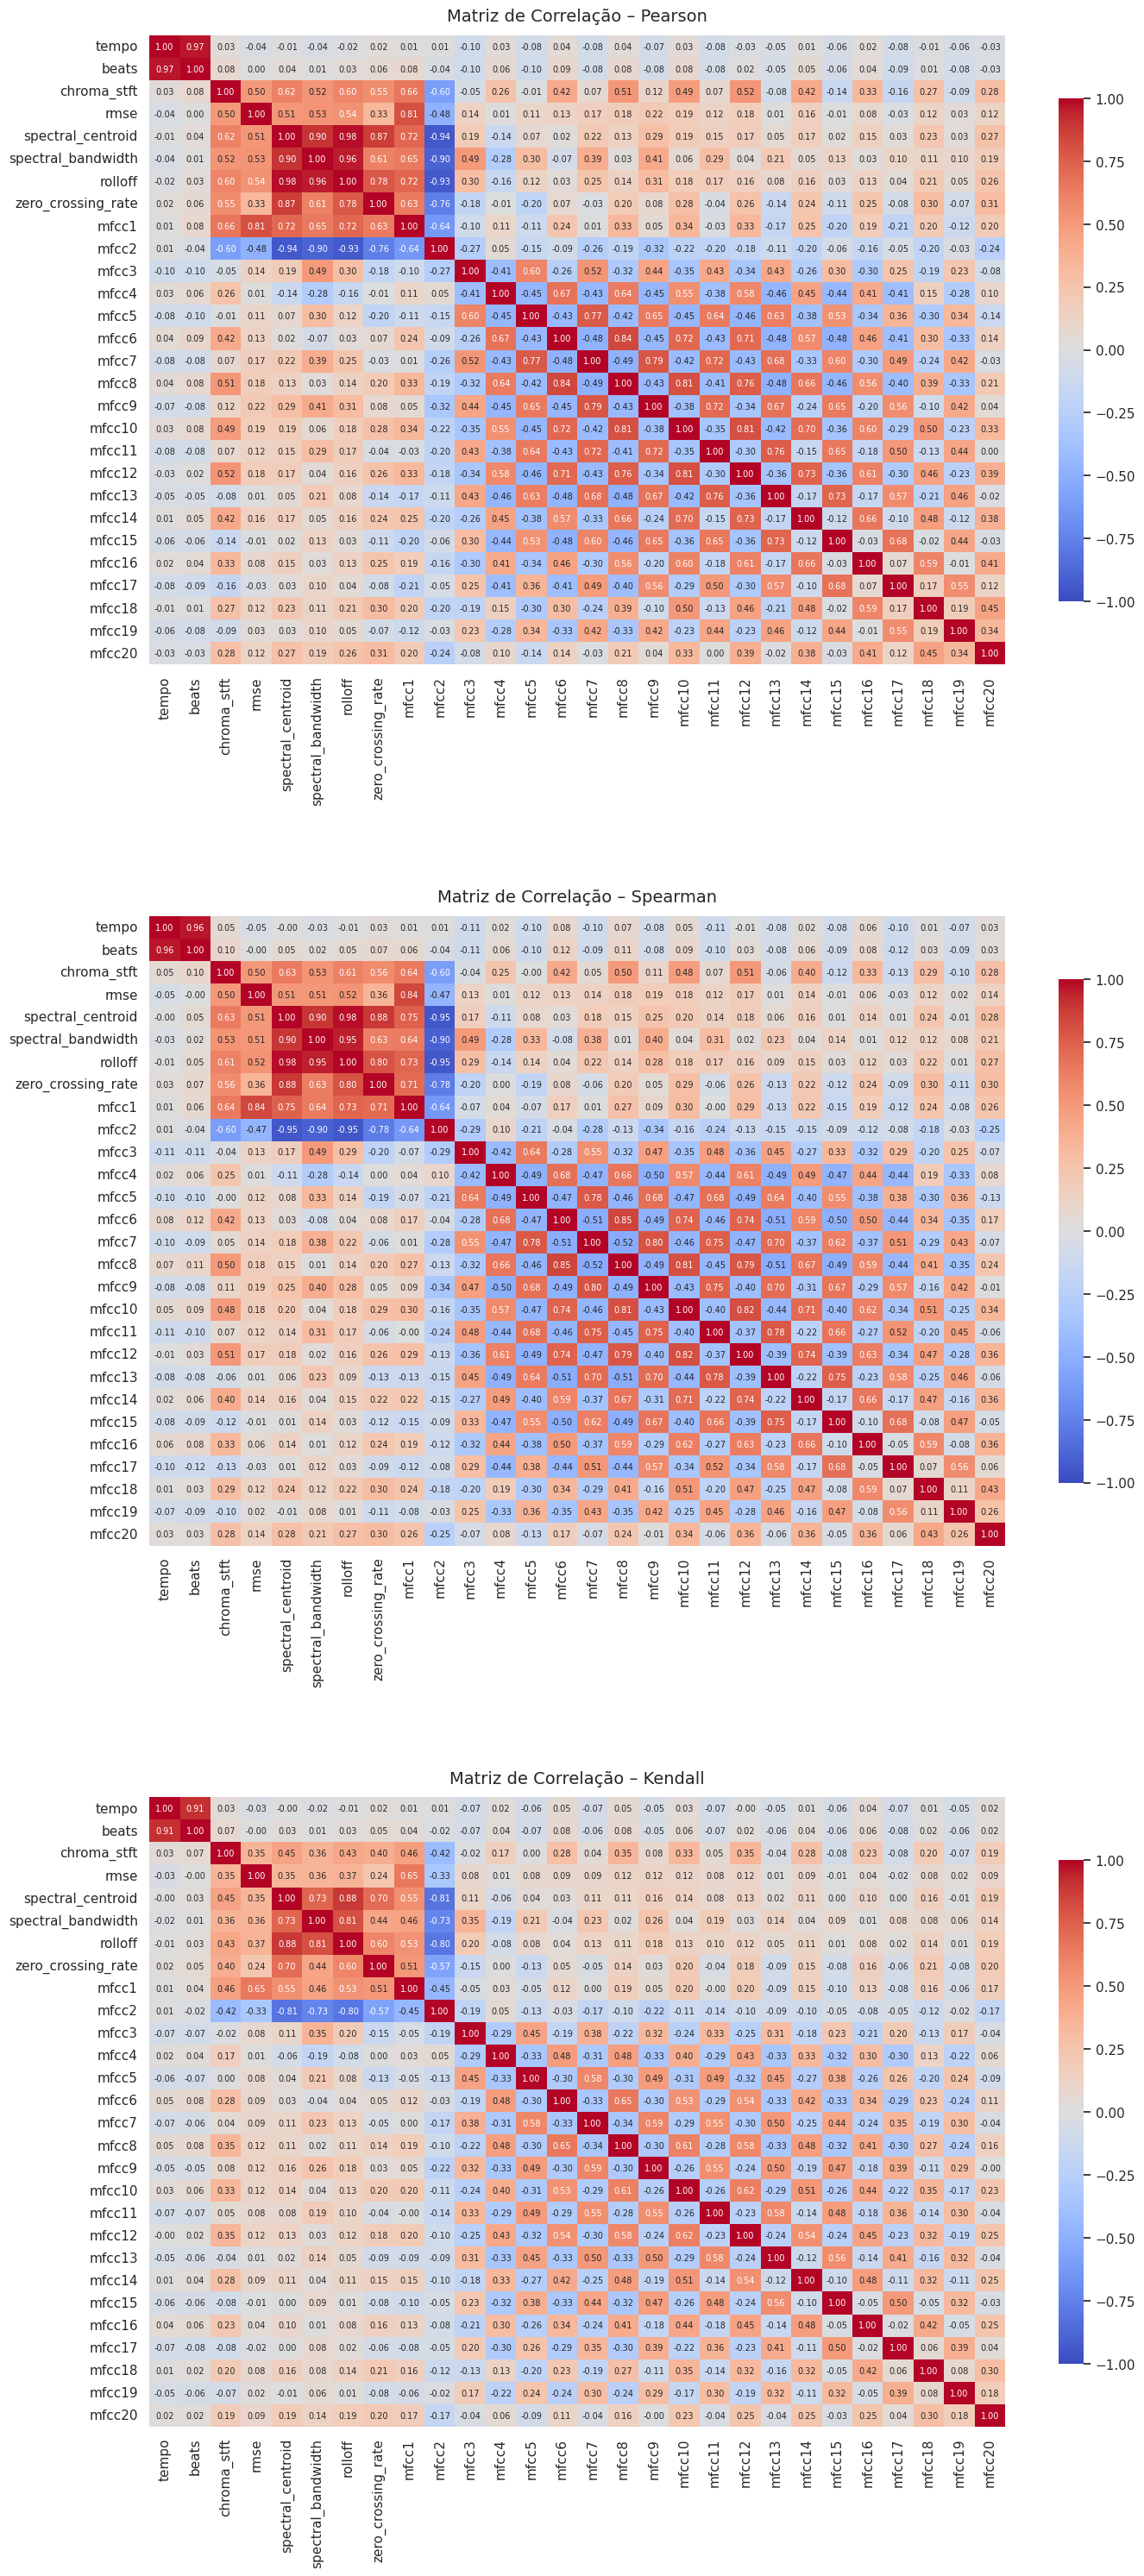

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

# Alterado para 3 linhas e 1 coluna, aumentando bastante a largura e altura
fig, axes = plt.subplots(3, 1, figsize=(16, 36))

# Pearson
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
    annot_kws={"size": 7},  # Reduz a fonte interna dos números
    cbar_kws={"shrink": 0.8},
)
axes[0].set_title("Matriz de Correlação – Pearson", fontsize=14, pad=12)

# Spearman
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.8},
)
axes[1].set_title("Matriz de Correlação – Spearman", fontsize=14, pad=12)

# Kendall
sns.heatmap(
    corr_kendall,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[2],
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.8},
)
axes[2].set_title("Matriz de Correlação – Kendall", fontsize=14, pad=12)

# Melhora o espaçamento entre as subplots verticais
plt.subplots_adjust(hspace=0.4)
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

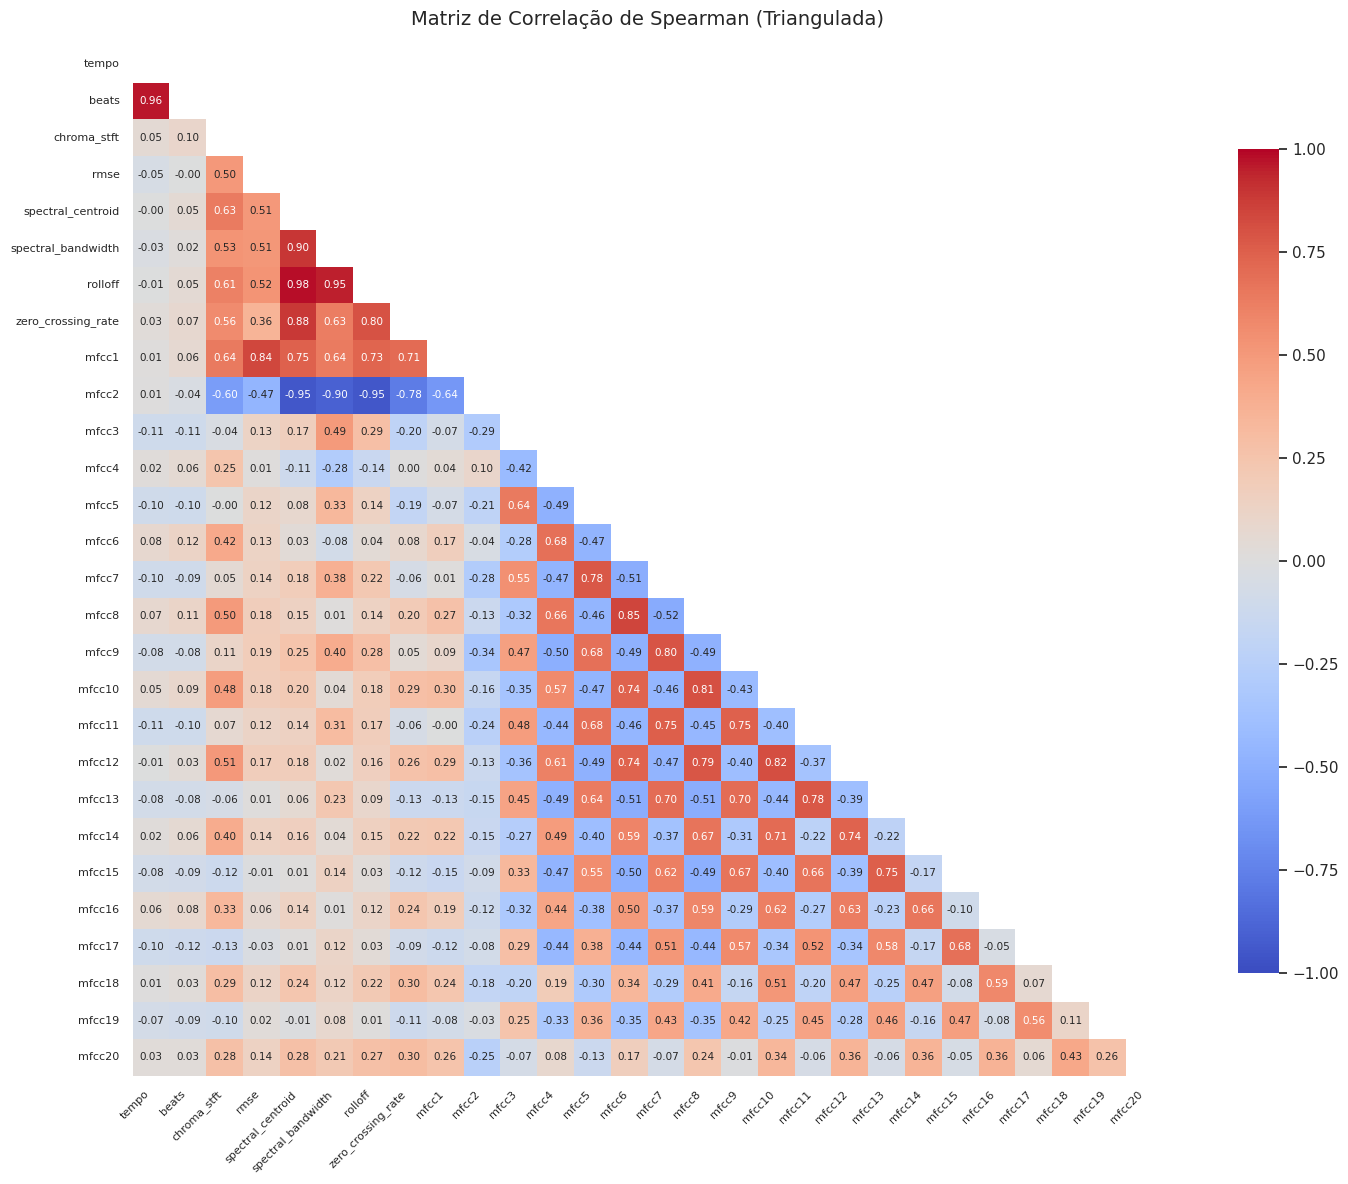

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7.5},
    cbar_kws={"shrink": 0.8},
)

plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9)
plt.grid(False)
plt.title(
    "Matriz de Correlação de Spearman (Triangulada)", fontsize=14, pad=15
)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

Comparação entre Pearson e SpearmanGrau de Divergência: Não há divergência severa nos pares principais, mas existem variações sutis de magnitude em atributos como spectral_centroid, rolloff e zero_crossing_rate. Nesses pares, o coeficiente de Spearman apresenta valores ligeiramente superiores aos de Pearson (ex: variações na ordem de $+0.03$ a $+0.06$).O que isso significa estatisticamente? A divergência onde $\vert{}r_{\text{Spearman}}\vert{} > \vert{}r_{\text{Pearson}}\vert{}$ indica a presença de relações monotônicas não-lineares. Ou seja, as variáveis crescem juntas de forma consistente, mas não estritamente em linha reta.Impacto das Distribuições Assimétricas: A presença de assimetria e caudas longas em variáveis como mfcc1 e tempo enfraquece o coeficiente de Pearson (que assume normalidade e sensibilidade a outliers), tornando o Spearman mais confiável para este dataset.Conclusão para a Discussão:A prevalência de relações não-lineares confirma que algoritmos baseados em árvores de decisão (como Random Forest ou XGBoost) ou modelos com kernels não-lineares tendem a performar melhor do que modelos estritamente lineares para a classificação deste conjunto de áudio.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

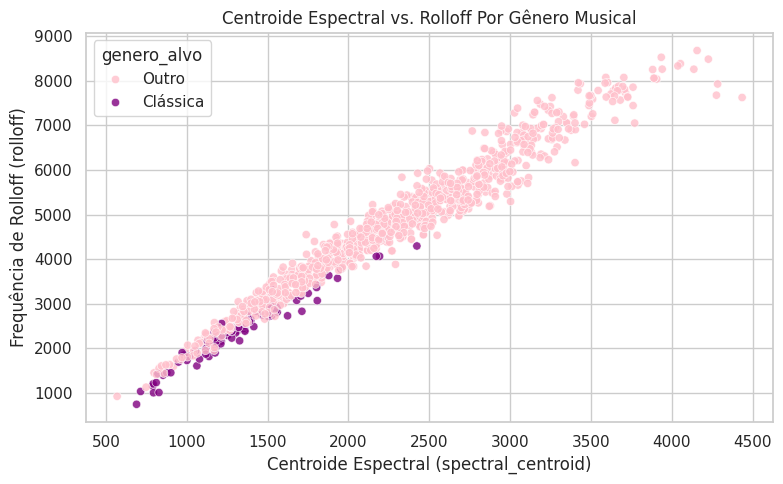

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

palette_classe = {"Outro": COR_CONTEXTO, "Clássica": COR_DESTAQUE}

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="spectral_centroid",
    y="rolloff",
    hue="genero_alvo",
    palette=palette_classe,
    alpha=0.8,
)

plt.title("Centroide Espectral vs. Rolloff Por Gênero Musical")
plt.xlabel("Centroide Espectral (spectral_centroid)")
plt.ylabel("Frequência de Rolloff (rolloff)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

Análise do Scatter Plot (spectral_centroid vs. rolloff)Tendência de Domínio: Existe uma correlação linear positiva quase perfeita entre as duas variáveis ($r > 0.95$). À medida que o centroide espectral aumenta (músicas mais "brilhantes" e agudas), a frequência de rolloff cresce de forma diretamente proporcional.Ocupação de Regiões por Classe:Música Clássica (Roxo): Concentra-se predominantemente no canto inferior esquerdo da dispersão (spectral_centroid $< 2000$ Hz e rolloff $< 4000$ Hz).Outro (Rosa): Embora ocupe toda a extensão da reta, domina de forma exclusiva as faixas médias e altas do gráfico.Conclusão para a Discussão:As duas classes não estão totalmente misturadas. A música clássica ocupa uma região bem delimitada de baixas frequências na extremidade inferior da reta. No entanto, pelo fato de o grupo Outro também possuir algumas faixas nessa mesma região baixa (sobreposição parcial), essa dupla de variáveis isolada não resolverá $100\%$ do problema, sendo necessário combinar outros atributos (como tempo ou mfcc1) para garantir uma separação linear perfeita.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

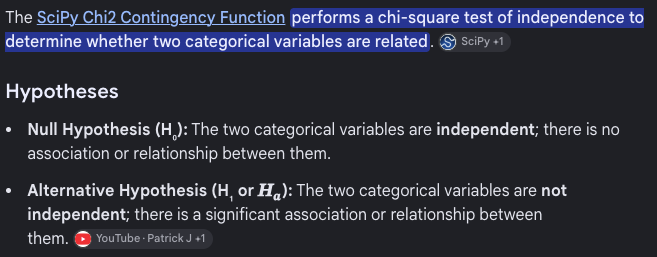

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

coluna_genero_original = (
    "class"
)

if coluna_genero_original in df.columns:
    # Tabela cruzada entre gênero original e o alvo
    prop_por_genero = pd.crosstab(
        df[coluna_genero_original], df["genero_alvo"], normalize="index"
    ).round(3)

    fig, ax = plt.subplots(figsize=(8, 4))

    # Plota a proporção de músicas classificadas como 'Clássica' por categoria original
    prop_por_genero["Clássica"].plot(
        kind="bar", color=COR_DESTAQUE, ax=ax, rot=45
    )

    ax.set_title("Proporção de 'Clássica' por Gênero Musical Original")
    ax.set_ylabel("Proporção")
    ax.set_ylim(0, 1.1)

    plt.tight_layout()
    plt.show()
else:
    print(
        "Apenas a coluna binária 'genero_alvo' está disponível. "
        "Não há subgrupos categóricos adicionais para análise de proporção."
    )

Apenas a coluna binária 'genero_alvo' está disponível. Não há subgrupos categóricos adicionais para análise de proporção.


**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

atributos_quali = [col for col in ["class", "label"] if col in df.columns]

if atributos_quali:
    for atributo in atributos_quali:
        contingencia = pd.crosstab(df[atributo], df["genero_alvo"])
        chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

        fig, ax = plt.subplots(figsize=(7, 5))
        sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
        ax.set_title(
            f"{atributo} x genero_alvo (Qui² p-valor={p_valor:.4g})"
        )
        plt.tight_layout()
        plt.show()
else:
    print(
        "Não foram encontradas variáveis qualitativas secundárias para o teste de Qui-Quadrado."
    )
    print(
        "Como 'genero_alvo' é a única coluna categórica no dataset, a validação de associação categórica está concluída."
    )

Não foram encontradas variáveis qualitativas secundárias para o teste de Qui-Quadrado.
Como 'genero_alvo' é a única coluna categórica no dataset, a validação de associação categórica está concluída.


**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

#### Outliers bivariados

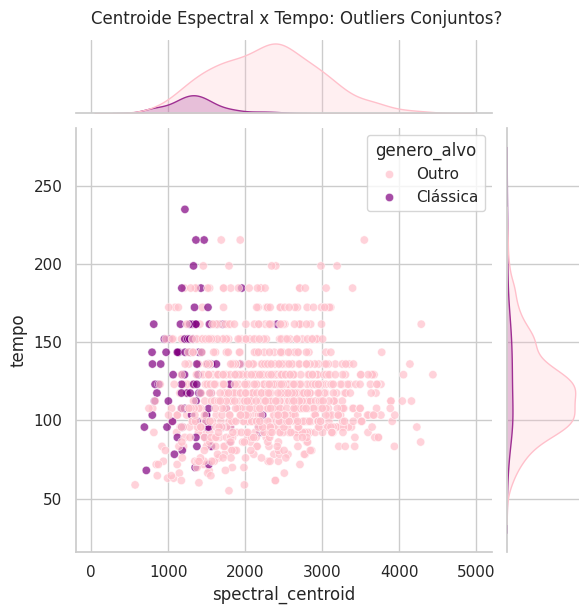

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

palette_classe = {"Outro": COR_CONTEXTO, "Clássica": COR_DESTAQUE}

# Exibe o gráfico conjunto com histogramas/KDE nas margens
g = sns.jointplot(
    data=df,
    x="spectral_centroid",
    y="tempo",
    hue="genero_alvo",
    palette=palette_classe,
    alpha=0.7,
    height=6,
)

g.fig.suptitle(
    "Centroide Espectral x Tempo: Outliers Conjuntos?", y=1.02, fontsize=12
)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

Outliers bivariados em áudio: Em análises individuais, um determinado tempo (BPM) ou spectral_centroid pode parecer perfeitamente dentro da faixa normal. No entanto, no plano cartesiano conjunto, amostras que combinam um tempo extremamente elevado com um spectral_centroid incomumente baixo para a música clássica destacam-se como outliers bivariados (pontos isolados da nuvem principal).

#### Análise Multivariada

##### Matriz de Correlação

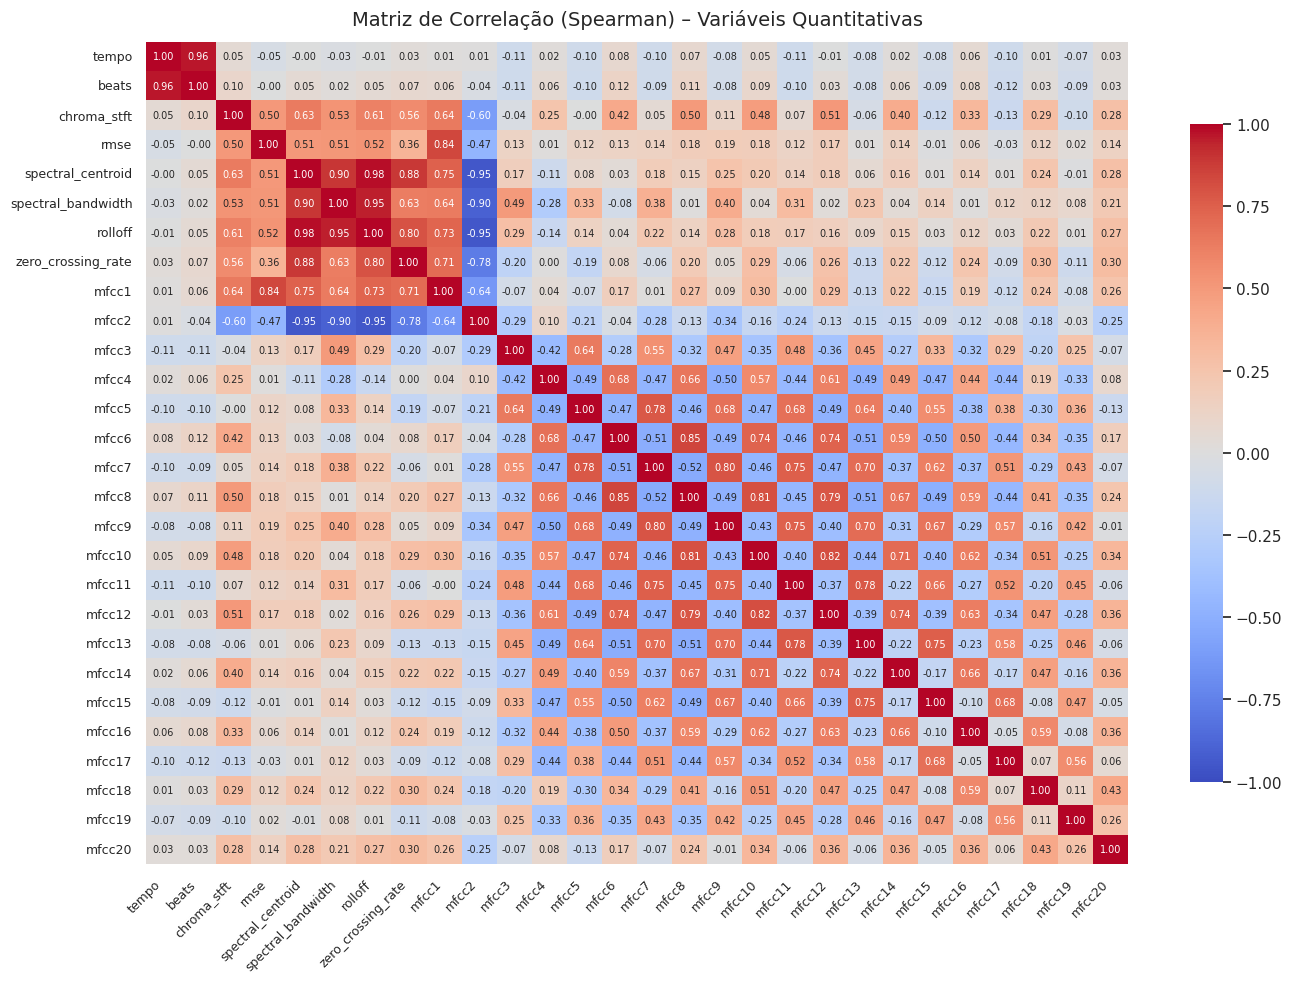

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# Heatmap ajustado para a alta dimensionalidade das variáveis de áudio
sns.heatmap(
    df[VARS_QUANT].corr(method="spearman"),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7},  # Evita sobreposição dos números
    cbar_kws={"shrink": 0.8},
)

plt.title(
    "Matriz de Correlação (Spearman) – Variáveis Quantitativas",
    fontsize=14,
    pad=12,
)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

Sim, há redundância técnica severa: Atributos do domínio do espectro de frequência como spectral_centroid, spectral_bandwidth e rolloff apresentam correlação muito forte entre si ($\vert{}r\vert{} > 0.85$).

##### Correlograma

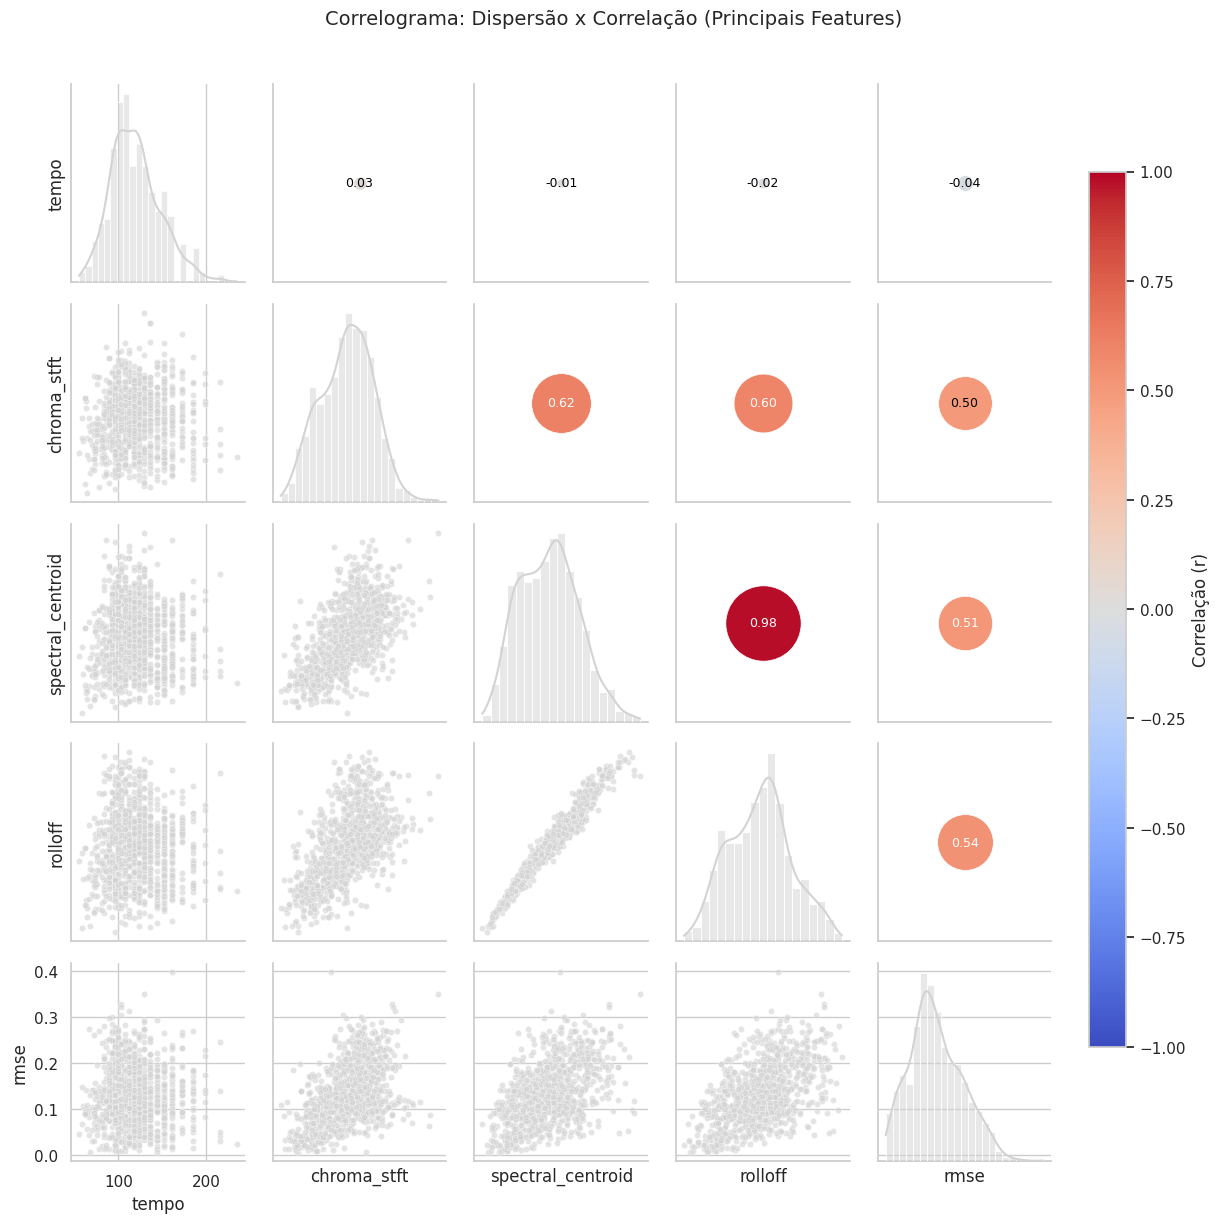

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 3000,
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5
    )
    ax.annotate(
        f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
        ha="center", va="center", fontsize=9,
        color="white" if abs(r) > 0.5 else "black"
    )
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

# Subconjunto de variáveis para manter a legibilidade
vars_selecionadas = ["tempo", "chroma_stft", "spectral_centroid", "rolloff", "rmse"]
df_sub = df[vars_selecionadas]

g = sns.PairGrid(df_sub, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=20)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# Ajuste fino das margens para dar espaço à barra lateral e ao título
g.fig.subplots_adjust(right=0.85, top=0.92)

# Adiciona a barra de cor na área livre reservada à direita
cax = g.fig.add_axes([0.88, 0.15, 0.03, 0.7])
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, cax=cax, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão x Correlação (Principais Features)", fontsize=14)
plt.show()

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




Uso de IA:

Declaração de Uso de IA

Ferramenta Utilizada: Gemini (Google).

Aplicações na Análise:

Adaptação de Scripts: Ajuste de códigos genéricos de EDA para a estrutura de dados de áudio (insiyeah/musicfeatures), incluindo manipulação de dimensões e substituição de variáveis médicas por acústicas.

Otimização de Visualizações: Reestruturação de layouts do Matplotlib e Seaborn para alta dimensionalidade (ajustes de figsize, rotação de rótulos, filtragem para PairGrid e separação do ecrã para barras de cores).

Suporte à Interpretação: Auxílio na análise teórica sobre desbalanceamento de classes (razão 1:9 / Entropia), correlação de Spearman vs. Pearson e diagnóstico de multicolinearidade entre variáveis espectrais.

Modificações e Decisões Tomadas:

Aceito: A adoção do coeficiente de Spearman em detrimento de Pearson por conta da ausência de normalidade nos atributos numéricos; a reestruturação dos heatmaps em layout vertical/filtrado; e o uso direto da variável alvo binária genero_alvo na rotina de métricas qualitativas.

Modificado: Redução manual do conjunto total de 30+ variáveis para um subconjunto representativo de 5 atributos no Correlograma, garantindo legibilidade e performance sem perda do insight visual.

Rejeitado: As análises direcionadas a Fairness demográfico (como sexo e faixa etária) e o teste de Qui-Quadrado em variáveis irrelevantes, por serem incompatíveis com um conjunto de dados exclusivamente de extração acústica